## 1. Pull issues from GitHub
Hitting the GitHub search API, paging through to grab real issues only (no pull requests).

In [ ]:
import requests,time
from google.colab import userdata

token = userdata.get('GITHUB_TOKEN')
headers = {"Authorization" : f"Bearer {token}"}

#search endpoint
url = "https://api.github.com/search/issues"

all_issues = []
page = 1
max_pages = 10

while page <= max_pages:
    params = {
        "q" : "repo:pandas-dev/pandas is:issue", # real issues only not PR's
        "sort" : "created",
        "order" : "desc",
        "per_page" : 100,
        "page" : page
    }
    response = requests.get(url, headers = headers, params = params)

    if response.status_code != 200:
      print(f"Page {page} failed: {response.status_code} Stopping")
      print(response.json())
      break

    batch = response.json()["items"]
    if not batch:
      print(f"Page {page} empty Done")
      break
    all_issues.extend(batch)
    print(f"Page {page}:{len(batch)} issues.total: {len(all_issues)}. rate limitleft : {response.headers.get('X-RateLimit-Remaining')}")

    page += 1
    time.sleep(2) # search is rate-limited harder, longer stops

print(f"\nDone. Collected {len(all_issues)} real issues.")

Page 1:100 issues.total: 100. rate limitleft : 29
Page 2:100 issues.total: 200. rate limitleft : 28
Page 3:100 issues.total: 300. rate limitleft : 27
Page 4:100 issues.total: 400. rate limitleft : 26
Page 5:100 issues.total: 500. rate limitleft : 25
Page 6:100 issues.total: 600. rate limitleft : 24
Page 7:100 issues.total: 700. rate limitleft : 23
Page 8:100 issues.total: 800. rate limitleft : 22
Page 9:100 issues.total: 900. rate limitleft : 21
Page 10:100 issues.total: 1000. rate limitleft : 20

Done. Collected 1000 real issues.


Quick check: how many issues did we actually get?

In [ ]:
print("Issues safely collected",len(all_issues))

Issues safely collected 1000


## 2. Raw layer
Dump every issue into a database exactly as it came. Untouched, our source of truth.

In [ ]:
import sqlite3
import json

#creates/connect to database file
conn = sqlite3.connect("github.db")
cur = conn.cursor()

cur.execute("DROP TABLE IF EXISTS raw_issues")
cur.execute("""CREATE TABLE raw_issues(id INTEGER,raw_json TEXT)""")

for issue in all_issues:
    cur.execute("INSERT INTO raw_issues(id, raw_json) values (?,?)",(issue["id"], json.dumps(issue)))

conn.commit()

cur.execute("SELECT COUNT(*) FROM raw_issues")
print("Rows in raw_issues:", cur.fetchone()[0])

Rows in raw_issues: 1000


## 3. Clean layer
Keep only the fields we need, fix dates, drop pull requests hiding as issues.

In [ ]:
import pandas as pd

raw_df = pd.read_sql("select raw_json FROM raw_issues", conn)

rows = []
for raw in raw_df["raw_json"]:
     issue = json.loads(raw) # turning back text into a python object.

     if "pull_request" in issue:
         continue

     rows.append({"id" : issue["id"],
                  "state" : issue["state"],
                   "created_at" : issue["created_at"],
                    "closed_at" : issue.get("closed_at")})
clean_df = pd.DataFrame(rows)
#convert date text into real date times
clean_df["created_at"] = pd.to_datetime(clean_df["created_at"])
clean_df["closed_at"]  = pd.to_datetime(clean_df["closed_at"])
#write the clean layer into its own table
clean_df.to_sql("clean_issues",conn, if_exists = "replace", index = False)

print("Raw issues:", len(raw_df))
print("Clean issues after dropping PRs:", len(clean_df))
print(clean_df.head())
print("\nOpen issues with no closed_at (expected to be null):")
print(clean_df[clean_df["state"] == "open"].head(3))

Raw issues: 1000
Clean issues after dropping PRs: 1000
           id state                created_at closed_at
0  5895623035  open 2026-10-17 06:20:29+00:00       NaT
1  5895616335  open 2026-10-17 06:19:23+00:00       NaT
2  5894664462  open 2026-10-17 04:05:05+00:00       NaT
3  5893149377  open 2026-10-17 00:34:05+00:00       NaT
4  5884932233  open 2026-10-16 13:23:51+00:00       NaT

Open issues with no closed_at (expected to be null):
           id state                created_at closed_at
0  5895623035  open 2026-10-17 06:20:29+00:00       NaT
1  5895616335  open 2026-10-17 06:19:23+00:00       NaT
2  5894664462  open 2026-10-17 04:05:05+00:00       NaT


Check the split: how many open vs closed?

In [ ]:
print("Total clean issues", len(clean_df))
print("\nBreakdown by state:")
print(clean_df["state"].value_counts())
print("\nClosed issues that have a close date:")
print(clean_df["closed_at"].notna().sum())

Total clean issues 1000

Breakdown by state:
state
closed    768
open      232
Name: count, dtype: int64

Closed issues that have a close date:
768


## 4. Reporting layer - Metric 1
Count opened and closed per week into one small table.

In [ ]:
#read the clean data back
clean_df = pd.read_sql("select * from clean_issues", conn)
clean_df["created_at"] = pd.to_datetime(clean_df["created_at"])
clean_df["closed_at"] = pd.to_datetime(clean_df["closed_at"])

opened = (clean_df.set_index("created_at")
                  .resample("W")
                  .size()
                  .rename("opened"))
closed = (clean_df.set_index("closed_at")
                  .resample("W")
                  .size()
                  .rename("closed"))

#combine into one
report_weekly = pd.concat([opened,closed], axis = 1).fillna(0).astype(int)
report_weekly = report_weekly.reset_index().rename(columns = {"index":"week"})
report_weekly = report_weekly.rename(columns = {report_weekly.columns[0]: "week"})

#save the reporting layer
report_weekly.to_sql("report_weekly", conn, if_exists = "replace", index = False)


print("Weeks in report:" ,len(report_weekly))
print(report_weekly.tail(10))



Weeks in report: 64
                        week  opened  closed
54 2026-08-16 00:00:00+00:00      17      26
55 2026-08-23 00:00:00+00:00       6      10
56 2026-08-30 00:00:00+00:00      17      12
57 2026-09-06 00:00:00+00:00      30      23
58 2026-09-13 00:00:00+00:00      11      16
59 2026-09-20 00:00:00+00:00      11      15
60 2026-09-27 00:00:00+00:00      15      30
61 2026-10-04 00:00:00+00:00      13      16
62 2026-10-11 00:00:00+00:00      16      15
63 2026-10-18 00:00:00+00:00      18      17


Chart 1: is the backlog growing or shrinking?

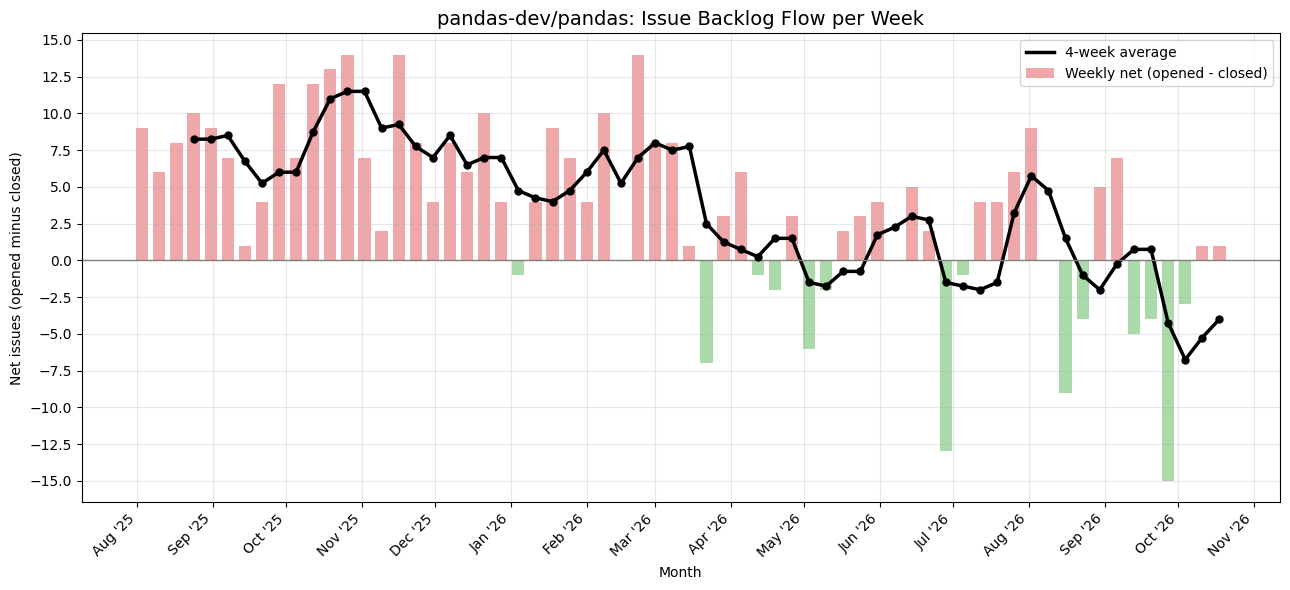

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator

report = pd.read_sql("select * from report_weekly", conn)
report["week"] = pd.to_datetime(report["week"])

#the net flow : positive = backlog grew that week, negative = shrink
report["net"] = report["opened"] - report["closed"]

#a 4-week rolling average
report["net_trend"] = report["net"].rolling(window = 4).mean()

fig, ax = plt.subplots(figsize = (13,6))

colors = ["#d62728" if v > 0 else "#2ca02c" for v in report["net"]]
ax.bar(report["week"], report["net"], width = 5, color=colors, alpha = 0.4, label = "Weekly net (opened - closed)")

ax.plot(report["week"], report["net_trend"], color = 'black', linewidth = 2.5, label = "4-week average")


ax.scatter(report["week"], report["net_trend"],color = "black", s =25, zorder = 5)
ax.axhline(0, color = "gray", linewidth = 1)

# y-axis: labelled line every 2.5
ax.yaxis.set_major_locator(MultipleLocator(2.5))

# x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
plt.setp(ax.get_xticklabels(), rotation = 45, ha = "right")


ax.set_title("pandas-dev/pandas: Issue Backlog Flow per Week", fontsize = 14)
ax.set_xlabel("Month")
ax.set_ylabel("Net issues (opened minus closed)")
ax.legend()
ax.grid(True, alpha=0.3)


plt.tight_layout()
plt.savefig("backlog_flow.png", dpi=150)
plt.show()

## 5. Reporting layer - Metric 2
For closed issues, work out how long each took, median per open-month.

In [ ]:
clean_df = pd.read_sql("SELECT * FROM clean_issues", conn)
clean_df["created_at"] = pd.to_datetime(clean_df["created_at"])
clean_df["closed_at"] = pd.to_datetime(clean_df["closed_at"])

# working only with closed issues
closed_df = clean_df[clean_df["closed_at"].notna()].copy()

#how many days each issue stayed open
closed_df["days_to_close"] = (closed_df["closed_at"] - closed_df["created_at"]).dt.days


ttc = (closed_df.set_index("created_at").resample("ME")["days_to_close"]
       .median()
       .round(1)
       .rename("median_days_to_close"))

report_monthly = ttc.reset_index()
report_monthly = report_monthly.rename(columns = {report_monthly.columns[0] : "month"})
report_monthly.to_sql("report_monthly_ttc", conn, if_exists = "replace", index = False)

print(report_monthly)


                       month  median_days_to_close
0  2025-07-31 00:00:00+00:00                 216.0
1  2025-08-31 00:00:00+00:00                   4.0
2  2025-09-30 00:00:00+00:00                  12.5
3  2025-10-31 00:00:00+00:00                  10.0
4  2025-11-30 00:00:00+00:00                  23.5
5  2025-12-31 00:00:00+00:00                  13.0
6  2026-01-31 00:00:00+00:00                   4.0
7  2026-02-28 00:00:00+00:00                   8.0
8  2026-03-31 00:00:00+00:00                  12.5
9  2026-04-30 00:00:00+00:00                  11.0
10 2026-05-31 00:00:00+00:00                  34.5
11 2026-06-30 00:00:00+00:00                   2.0
12 2026-07-31 00:00:00+00:00                   8.0
13 2026-08-31 00:00:00+00:00                   5.0
14 2026-09-30 00:00:00+00:00                   6.0
15 2026-10-31 00:00:00+00:00                   0.0


Chart 2: how fast do issues typically get closed?

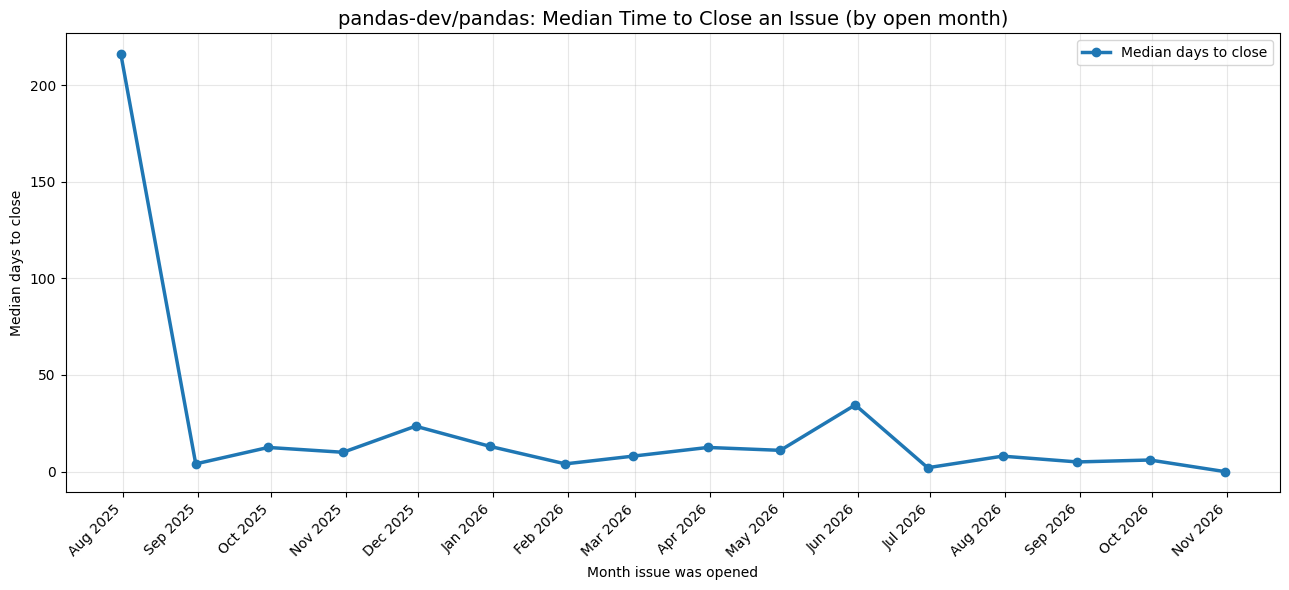

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

report2 = pd.read_sql("SELECT * FROM report_monthly_ttc", conn)
report2["month"] = pd.to_datetime(report2["month"])

fig, ax = plt.subplots(figsize=(13, 6))

# the main trend line with a dot on every real data point
ax.plot(report2["month"], report2["median_days_to_close"],
        color="#1f77b4", linewidth=2.5, marker="o", markersize=6, label="Median days to close")

report2 = report2.iloc[1:-1]


ax.set_title("pandas-dev/pandas: Median Time to Close an Issue (by open month)", fontsize=14)
ax.set_xlabel("Month issue was opened")
ax.set_ylabel("Median days to close")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("time_to_close.png", dpi=150)
plt.show()